# Probability in Python
## Samples, Empirical Distributions, Conditional Structure and Monte Carlo

**Practical 5 — core approximately 70 minutes, optional extension up to 85 minutes**

The probability lecture gives us the mathematical language:

$$
\text{distribution}
\rightarrow
\text{sample}
\rightarrow
\text{summary / comparison}
\rightarrow
\text{decision}.
$$

This practical asks what those objects look like in Python.

We will use one small synthetic system throughout the session: **request latency** for a service that has
a fast cache-hit path and a slower cache-miss path.

The goal is not to memorize distribution APIs. It is to learn how to move between:

$$
P
\longrightarrow
X_1,\ldots,X_n
\longrightarrow
\widehat P_n
\longrightarrow
\text{empirical evidence}.
$$

### Learning outcomes

After this session you should be able to:

1. distinguish a probability model from one realized sample
2. estimate probabilities and expectations from simulated or observed data
3. read a histogram and an empirical CDF as different views of the same sample
4. explain why mean and standard deviation do not describe the whole distribution
5. distinguish marginal from conditional summaries
6. estimate a quantity with Monte Carlo simulation and inspect convergence
7. compare complete distributions when a single summary is insufficient

### Requirements

`numpy`, `pandas`, `matplotlib`.  
`scipy` is used only in the optional distribution-comparison section.

### Session plan

| Time | Part | What you should discover |
|---|---|---|
| 0–10 min | 1. Model → sample | a distribution is not the same object as a dataset |
| 10–25 min | 2. Empirical distribution | histogram, ECDF, quantiles, tail probabilities |
| 25–40 min | 3. Conditional structure | a marginal distribution can hide two very different regimes |
| 40–60 min | 4. Monte Carlo | probability and expectation can be numerical computations |
| 60–70 min | 5. Exercise + exit challenge | transfer the workflow to a modified system |
| 70–85 min | 6. Optional: compare distributions | KL and Wasserstein answer different questions |

The **core is Parts 1–5**.  
Part 6 is deliberately optional so the practical still fits one class.

## 0. Environment

In [1]:
import sys
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Python:   ", sys.version.split()[0])
print("NumPy:    ", np.__version__)
print("pandas:   ", pd.__version__)
print("Platform: ", platform.platform())

/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-xk0ek2e7 because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Python:    3.13.5
NumPy:     2.3.5
pandas:    2.2.3
Platform:  Linux-6.18.44-x86_64-with-glibc2.41


In Practical 3 we already introduced the modern random-number interface:

```python
rng = np.random.default_rng(seed)
```

We will **not** repeat the RNG internals here. Random sampling is now simply a tool for exploring
probability models.

In [2]:
rng = np.random.default_rng(2026)

---
## 1. From a probability model to one realized sample

Suppose a request can follow one of two paths:

- **cache hit** with probability $p=0.72$
- **cache miss** with probability $1-p$

Conditional on the path:

$$
L \mid \text{hit} \sim \mathcal N(55, 8^2)
$$

and

$$
L \mid \text{miss} = 55 + E,
\qquad
E \sim \operatorname{Exponential}(\text{scale}=120).
$$

Here $L$ is latency in milliseconds.

This is a **model**. A dataset appears only after we draw observations from it.

In [3]:
def simulate_requests(
    n: int,
    *,
    hit_probability: float = 0.72,
    miss_scale_ms: float = 120.0,
    seed: int | None = None,
) -> pd.DataFrame:
    local_rng = np.random.default_rng(seed)

    cache_hit = local_rng.random(n) < hit_probability

    latency = np.empty(n, dtype=float)

    n_hit = cache_hit.sum()
    n_miss = n - n_hit

    latency[cache_hit] = local_rng.normal(
        loc=55.0,
        scale=8.0,
        size=n_hit,
    )

    latency[~cache_hit] = (
        55.0
        + local_rng.exponential(
            scale=miss_scale_ms,
            size=n_miss,
        )
    )

    # Negative values are practically impossible here, but latency itself cannot be negative.
    latency = np.clip(latency, 0.0, None)

    return pd.DataFrame(
        {
            "cache_hit": cache_hit,
            "latency_ms": latency,
        }
    )

In [4]:
small = simulate_requests(30, seed=1)
large = simulate_requests(5_000, seed=1)

small.head()

,cache_hit,latency_ms
0,True,54.019325
1,False,152.239210
2,True,71.942710
3,False,323.937893
4,True,46.103834


The model is unchanged, but the two samples are not.

A sample mean is therefore a **random quantity**: another sample from the same model usually gives
another value.

In [5]:
summary = pd.DataFrame(
    {
        "n": [len(small), len(large)],
        "mean_ms": [small["latency_ms"].mean(), large["latency_ms"].mean()],
        "median_ms": [small["latency_ms"].median(), large["latency_ms"].median()],
        "p95_ms": [
            small["latency_ms"].quantile(0.95),
            large["latency_ms"].quantile(0.95),
        ],
    },
    index=["small sample", "large sample"],
)

summary

,n,mean_ms,median_ms,p95_ms
small sample,30,86.731825,57.257831,240.673793
large sample,5000,87.747526,58.875825,255.821003


A larger sample does not make the underlying process “less random”.

It makes the **empirical summaries** of that process more stable.

---
## 2. The empirical distribution

A histogram answers roughly:

> where did the observations fall?

An empirical cumulative distribution function (ECDF) answers:

> what fraction of observations are at or below a threshold $x$?

For observations $x_1,\dots,x_n$,

$$
\widehat F_n(x)
=
\frac{1}{n}
\sum_{i=1}^{n}
\mathbf 1[x_i \le x].
$$

In [6]:
def ecdf(values):
    x = np.sort(np.asarray(values))
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y

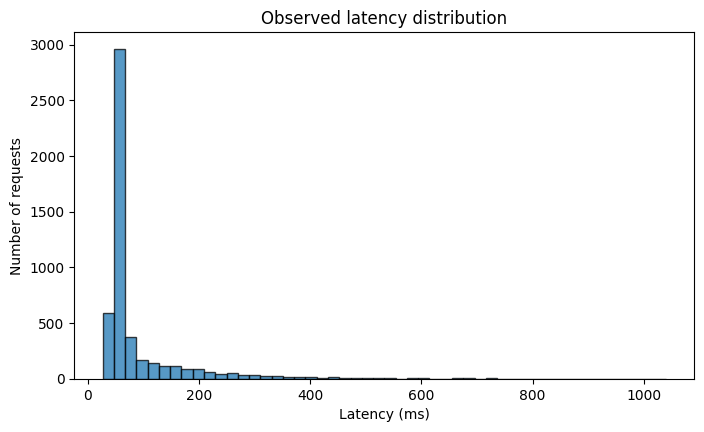

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.hist(
    large["latency_ms"],
    bins=50,
    edgecolor="black",
    alpha=0.75,
)

ax.set(
    title="Observed latency distribution",
    xlabel="Latency (ms)",
    ylabel="Number of requests",
)

plt.show()

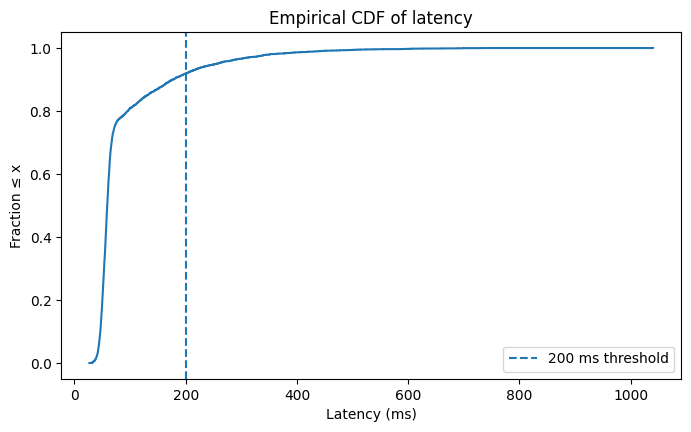

In [8]:
x, y = ecdf(large["latency_ms"])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.step(x, y, where="post")

ax.axvline(200, linestyle="--", label="200 ms threshold")

ax.set(
    title="Empirical CDF of latency",
    xlabel="Latency (ms)",
    ylabel="Fraction ≤ x",
)

ax.legend()
plt.show()

The ECDF immediately supports probability questions.

For example,

$$
P(L>200)
$$

is estimated by the observed fraction of requests above 200 ms.

In [9]:
tail_probability = (large["latency_ms"] > 200).mean()

print(f"Estimated P(latency > 200 ms): {tail_probability:.3f}")
print(f"Median latency:                 {large['latency_ms'].median():.1f} ms")
print(f"95th percentile:                {large['latency_ms'].quantile(0.95):.1f} ms")

Estimated P(latency > 200 ms): 0.081
Median latency:                 58.9 ms
95th percentile:                255.8 ms


### Mean is not the whole distribution

Latency is strongly right-skewed because cache misses can be much slower.

A mean can therefore hide behaviour that is obvious in the median, high quantiles or tail
probabilities.

For operational data, the question

> “What is the average?”

is often much weaker than

> “How often do we exceed a threshold?” or “What latency do 95% of requests stay below?”

In [10]:
latency_summary = large["latency_ms"].agg(
    ["mean", "median", "std", "min", "max"]
)

latency_summary["p90"] = large["latency_ms"].quantile(0.90)
latency_summary["p95"] = large["latency_ms"].quantile(0.95)
latency_summary["p99"] = large["latency_ms"].quantile(0.99)

latency_summary

mean        87.747526
median      58.875825
std         80.593682
min         26.951886
max       1040.176341
p90        177.527371
p95        255.821003
p99        440.317554
Name: latency_ms, dtype: float64

### Exercise A — sample size changes evidence, not the model

Generate two new samples from the **same** model:

- $n=100$
- $n=10\,000$

For each sample report:

1. mean latency
2. median latency
3. 95th percentile
4. estimated $P(L>200)$

Then answer in one sentence:

> Which summaries became more stable as $n$ increased, and why does this not mean the underlying
> latency distribution changed?

In [11]:
# Your solution starts here.

---
## 3. Marginal and conditional distributions

So far we treated all requests as one population.

But the model itself contains a hidden structure:

$$
P(L)
=
P(L \mid H)P(H)
+
P(L \mid H^c)P(H^c),
$$

where $H$ means “cache hit”.

The overall latency distribution is therefore a **mixture** of two conditional distributions.

In [12]:
large.groupby("cache_hit")["latency_ms"].agg(
    count="size",
    mean="mean",
    median="median",
    p95=lambda s: s.quantile(0.95),
)

,count,mean,median,p95
cache_hit,,,,
False,1401,172.001187,139.258960,396.791256
True,3599,54.949699,55.096967,67.700680


The marginal mean combines two very different regimes.

This is exactly why a marginal distribution can be misleading: an important explanatory variable may
be averaged away.

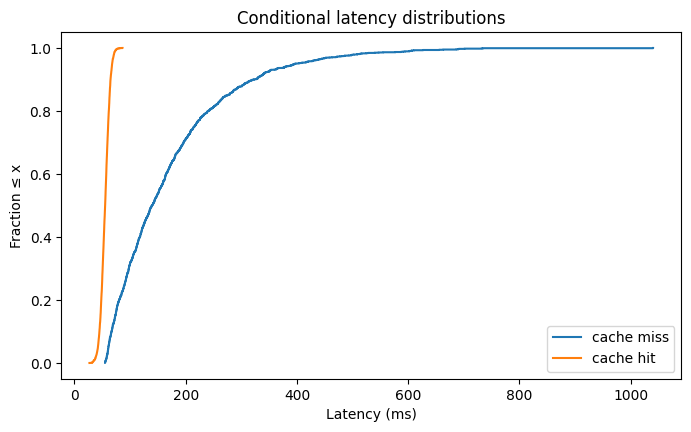

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))

for cache_hit, group in large.groupby("cache_hit"):
    x, y = ecdf(group["latency_ms"])
    label = "cache hit" if cache_hit else "cache miss"
    ax.step(x, y, where="post", label=label)

ax.set(
    title="Conditional latency distributions",
    xlabel="Latency (ms)",
    ylabel="Fraction ≤ x",
)

ax.legend()
plt.show()

### A conditional probability from the same table

Compare

$$
P(\text{miss})
$$

with

$$
P(\text{miss}\mid L>200).
$$

If very slow requests are disproportionately cache misses, conditioning on the latency event changes
the probability substantially.

In [14]:
p_miss = (~large["cache_hit"]).mean()

slow = large["latency_ms"] > 200
p_miss_given_slow = (~large.loc[slow, "cache_hit"]).mean()

print(f"P(cache miss):                 {p_miss:.3f}")
print(f"P(cache miss | latency > 200): {p_miss_given_slow:.3f}")

P(cache miss):                 0.280
P(cache miss | latency > 200): 1.000


### Exercise B — marginal versus conditional evidence

Compute and compare:

1. $P(L>150)$
2. $P(L>150 \mid \text{cache hit})$
3. $P(L>150 \mid \text{cache miss})$

Then answer:

> Why can the overall probability be a poor description of either subgroup?

In [15]:
# Your solution starts here.

---
## 4. Monte Carlo: probability as a numerical computation

Sometimes the quantity we want has no convenient closed form, or the system is too complicated for
an analytic derivation.

Monte Carlo uses repeated simulation:

$$
X^{(1)},\ldots,X^{(N)}
\sim P
$$

and approximates

$$
E[g(X)]
\approx
\frac{1}{N}
\sum_{i=1}^{N} g(X^{(i)}).
$$

A probability is just an expectation of an indicator:

$$
P(L>200)
=
E[\mathbf 1(L>200)].
$$

In [16]:
mc = simulate_requests(100_000, seed=7)

indicator = (mc["latency_ms"].to_numpy() > 200).astype(float)
running_estimate = np.cumsum(indicator) / np.arange(1, len(indicator) + 1)

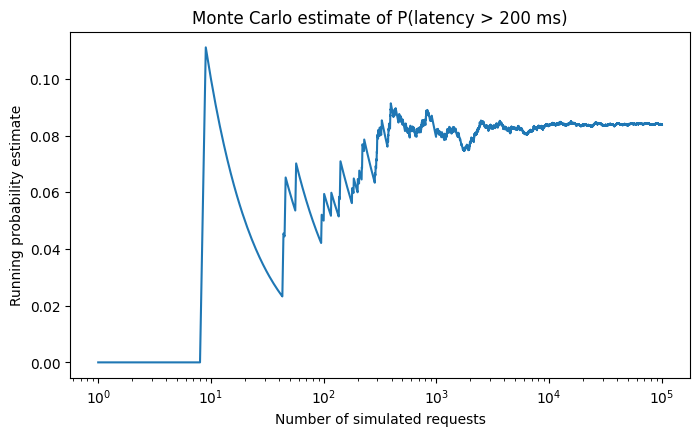

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(
    np.arange(1, len(running_estimate) + 1),
    running_estimate,
)

ax.set_xscale("log")

ax.set(
    title="Monte Carlo estimate of P(latency > 200 ms)",
    xlabel="Number of simulated requests",
    ylabel="Running probability estimate",
)

plt.show()

The estimate moves a lot at the beginning and becomes progressively more stable.

Monte Carlo is not “guessing randomly”. It is a numerical method whose uncertainty decreases as the
number of independent simulations grows.

### Expected penalty

Suppose an SLA creates a penalty

$$
C(L)
=
\begin{cases}
0, & L \le 150,\\
0.02(L-150), & L>150.
\end{cases}
$$

We can estimate the expected penalty directly from simulated requests.

In [18]:
latency = mc["latency_ms"].to_numpy()

penalty = np.where(
    latency > 150,
    0.02 * (latency - 150),
    0.0,
)

print(f"Estimated E[penalty]: {penalty.mean():.3f}")

Estimated E[penalty]: 0.306


### A vectorized experiment of experiments

Now ask a different question:

> If we observe 20 requests, what is the probability that their **average latency** exceeds 100 ms?

This is a probability about a random **sample mean**, not a probability about one request.

In [19]:
experiments = 20_000
requests_per_experiment = 20

sim = simulate_requests(
    experiments * requests_per_experiment,
    seed=8,
)

sample_means = (
    sim["latency_ms"]
    .to_numpy()
    .reshape(experiments, requests_per_experiment)
    .mean(axis=1)
)

estimated_probability = (sample_means > 100).mean()

print(
    "Estimated P(mean latency of 20 requests > 100 ms):",
    f"{estimated_probability:.3f}",
)

Estimated P(mean latency of 20 requests > 100 ms): 0.247


This is one reason simulation is so useful: we can change the **event** we care about without deriving a
new formula every time.

---
## 5. Exit challenge — compare two system configurations

A proposed change increases the cache-hit probability from `0.72` to `0.82` and reduces the miss
scale from `120 ms` to `90 ms`.

Simulate **50,000 requests** from:

1. the baseline system
2. the proposed system

Use the **same simulation function**.

For each system report:

- mean latency
- median latency
- 95th percentile
- estimated $P(L>200)$
- expected SLA penalty from Part 4
- $P(\text{cache miss}\mid L>200)$

Then:

1. make **one figure** that compares the two empirical latency distributions
2. write **three short conclusions**
3. state **one reason** why a lower mean alone would not be enough to evaluate the change

### Constraints

- use a fixed seed for reproducibility
- do not calculate probabilities by counting rows in a Python loop
- do not report more decimal places than the simulation precision justifies
- keep the model assumptions visible in the code

In [20]:
# Your solution starts here.

---
## 6. Optional extension — compare whole distributions

**Skip this section if the core practical has already used the available class time.**

The lecture introduced two different ideas:

- **KL divergence** — a directional discrepancy between probability distributions
- **Wasserstein distance** — a metric based on how far probability mass must move

They answer different questions.

In [21]:
try:
    from scipy import stats
    print("SciPy:", __import__("scipy").__version__)
except ImportError:
    stats = None
    print("SciPy is not installed; skip the optional section.")

SciPy: 1.17.0


### KL is directional

For two discrete probability vectors $p$ and $q$,

$$
D_{\mathrm{KL}}(p\|q)
=
\sum_i p_i \log\frac{p_i}{q_i}.
$$

The direction matters.

In [22]:
if stats is not None:
    p = np.array([0.70, 0.20, 0.10])
    q = np.array([0.50, 0.40, 0.10])

    print("KL(p || q):", stats.entropy(p, q))
    print("KL(q || p):", stats.entropy(q, p))

KL(p || q): 0.09690112952286008
KL(q || p): 0.10902275391337156


### Wasserstein keeps the units of the underlying space

For one-dimensional latency samples, the first Wasserstein distance is naturally interpreted in the
same unit as latency: milliseconds.

That makes it useful when the geometry of the measurement scale matters.

In [23]:
if stats is not None:
    baseline = simulate_requests(
        50_000,
        hit_probability=0.72,
        miss_scale_ms=120,
        seed=11,
    )

    proposed = simulate_requests(
        50_000,
        hit_probability=0.82,
        miss_scale_ms=90,
        seed=12,
    )

    w1 = stats.wasserstein_distance(
        baseline["latency_ms"],
        proposed["latency_ms"],
    )

    print(f"Wasserstein-1 distance: {w1:.2f} ms")

Wasserstein-1 distance: 17.26 ms


Neither number is a universal definition of “better”.

- KL depends on **relative probability mass** and is directional.
- Wasserstein uses a **ground distance** and asks how far mass must move.

The correct comparison depends on the analytical question.

---
## Summary

The important ideas are not the API calls.

### 1. Model and sample are different objects

A distribution describes possible behaviour. A dataset is one realized sample from that process.

### 2. The empirical distribution is already a model of evidence

Histograms, ECDFs, quantiles and tail frequencies describe different aspects of the observed sample.

### 3. Conditioning can change the story

A marginal distribution may hide subgroups with very different behaviour.

### 4. Probability can be computed

Monte Carlo turns expectations and probabilities into repeated numerical experiments when analytic
derivations are inconvenient.

### 5. One number is rarely enough

Mean, variance, quantiles, tail probabilities, KL and Wasserstein preserve different information.

The bridge to the next parts of the course is important:

```text
raw object
→ numerical representation
→ empirical distribution / geometry
→ comparison
→ dimensionality reduction / clustering / modelling
```

### Further reading

- [NumPy random Generator](https://numpy.org/doc/stable/reference/random/generator.html)
- [NumPy statistics](https://numpy.org/doc/stable/reference/routines.statistics.html)
- [SciPy statistical functions](https://docs.scipy.org/doc/scipy/reference/stats.html)
- [SciPy Wasserstein distance](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wasserstein_distance.html)
- [SciPy entropy / KL divergence](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.entropy.html)